# Premier League Athlete Training Load Analysis

In [ ]:
import datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm

pd.options.mode.chained_assignment = None

## Objective

This report aims to identify a method, or series of methods, for detecting whether a given athlete is "overreaching" during a training session. The usefulness of these methods in assessing risk of injury is also assessed.

Load management is an important aspect of athlete wellbeing, with research suggesting that proper load management can be critical to maximising athlete performance. Consistent "overreaching" efforts from an athlete, where they are training at an intensity higher than they are normally exposed to, has been shown to have negative affects on athlete health. This highlights a need for coaches to be well informed on athlete efforts, with effective monitoring allowing for improved planning of training. Highlighting when an athlete has been "overreaching" during a training session can inform decisions regarding future training sessions. Coaches may choose to schedule lower intensity training sessions, athletes may have increased recovery needs and choose to focus on extra recovery activities (e.g. stretching, physiotherapy, massage), and medical staff can be alerted to the fact that an athlete's health may need to be more closely monitored.

Research has also suggested that correct load management can reduce the risk of injury. This is especially important in academy actitivies, or when considering youth athletes, where the risk of injury from overtraining is often higher. Whilst load management does not act as a preventative measure for injuries, providing information on athlete workload may help coaches idenfity athletes at a higher risk of injury. This allows for mitigating strategies to be put in place before an injury occurs.

The methods outlined in this report can be applied in a live scenario. Players who have been identified as "overreaching" can be flagged to coaching staff as soon as a training session is finished. This allows for a quicker response from coaches, giving them the opportunity to implement changes in a training program that may help reduce injury risk.

## Data processing

### Data exploration

In [ ]:
df = pd.read_csv("data/anonymous.csv")

# Dataframe statistics
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

print(f"Columns: {', '.join(df.columns.tolist())}")

# Convert column types to useful types
df["date"] = pd.to_datetime(df["date"], format="%d/%m/%Y")
df["player"] = df["player"].astype(str)
df["position"] = df["position"].astype(str)
df["team_name"] = df["team_name"].astype(str)

# Summary statistics
num_players = len(df["player"].unique())
num_teams = len(df["team_name"].unique())
num_positions = len(df["position"].unique())
positions = list(df["position"].unique())
start_date = df["date"].min()
end_date = df["date"].max()

print()

print(f"Number of players: {num_players}")
print(f"Number of teams: {num_teams}")
print(f"Number of positions: {num_positions} ({', '.join(positions)})")

print(f"Start date: {start_date}")
print(f"End date: {end_date}")

Number of rows: 24826
Number of columns: 16
Columns: date, player, position, team_name, duration, total_distance_m, total_player_load, acc_2m_s_s_total_efforts, acc_3m_s_s_total_efforts, dec_2m_s_s_total_efforts, dec_3m_s_s_total_efforts, high_intensity_distance_m_v5_v6_m, sprint_distance_m_m, maximum_velocity_km_h, ima_cod_left, ima_cod_right

Number of players: 225
Number of teams: 8
Number of positions: 6 (Central Midfielder, Winger, Attacker, Full Back, Centre Back, Goal Keeper)
Start date: 2021-07-01 00:00:00
End date: 2023-06-30 00:00:00


### Distribution analysis

Analysing the distribution of features within the data can quickly reveal interesting patterns or insights. Plotting the distributions of each feature shows the spread of data, and can be used to identify outliers or incorrectly collected data points within the dataset.

Alongside the overall distribution plots, figures have also been created to show the differences in feature distributions between player positions. These reveal some insights into the differences between recorded activities across positon groups.

Firstly, Goal Keepers appear to have a different distribution of values across almost all features in the data, suggesting that their recorded activities follow a different pattern than other players. They tend to record a shorter distance travelled (`total_distance_m`) and also experience a lower accumulated player load (`total_player_load`). Additionally, they participate in less acceleration and deceleration events.

The plots also show that Wingers tend to accumulate more acceleration efforts during recorded activities than other positon groups. This is highlighted by the distribution tail extending past that of other positions for both `acc_2m_s_s_total_efforts` and `acc_3m_s_s_total_efforts`.

Finally, plotting the number of activities recorded per player helps to define the type of analysis that can be conducted. The plot shows that most athletes have recorded multiple activities, indicating that a long term analysis of per-athlete trends is viable without the need to aggregate activities across athletes.

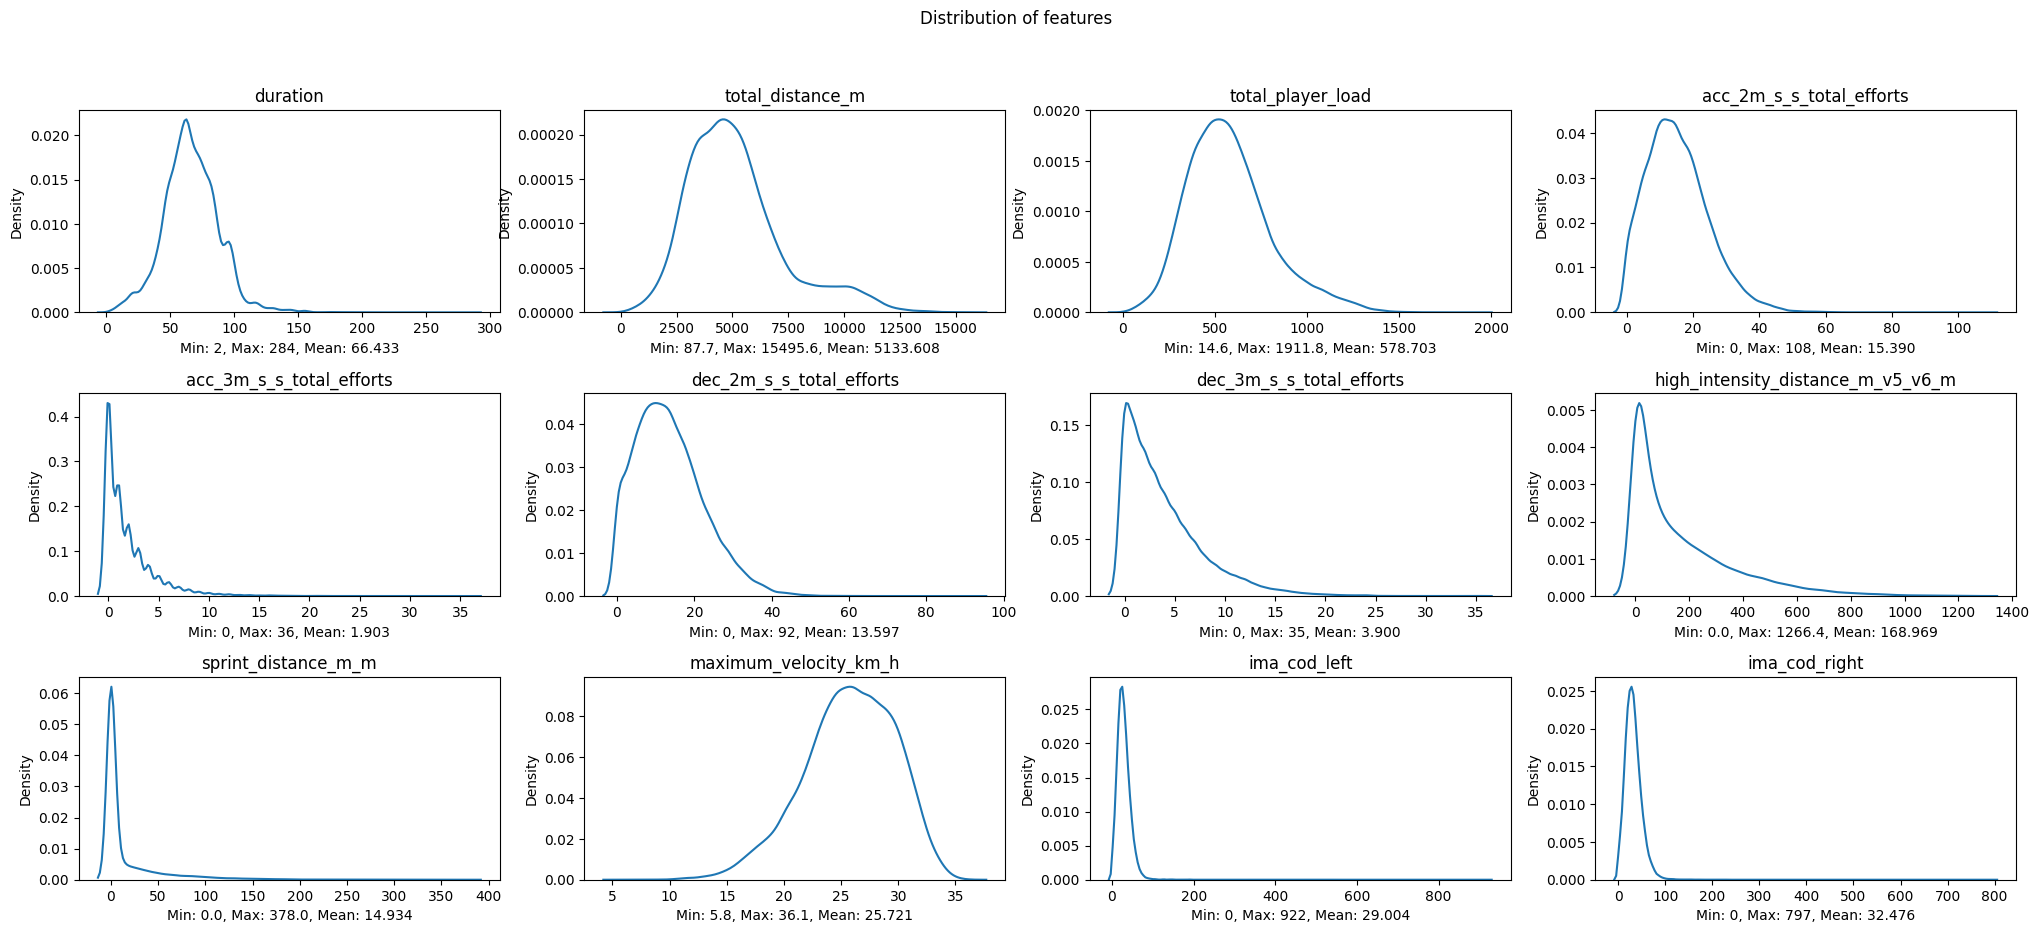

In [ ]:
# Plot overall distribution of features
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()

fig, axs = plt.subplots(3, 4, figsize=(25, 10))
plt.subplots_adjust(hspace=0.4)

for i, column in enumerate(numeric_columns):
    ax = axs[int(i / 4), i % 4]
    sns.kdeplot(df[column], ax=ax)

    column_min = df[column].min()
    column_max = df[column].max()
    column_mean = df[column].mean()

    ax.set_title(column)
    ax.set_xlabel(f"Min: {column_min}, Max: {column_max}, Mean: {column_mean:.3f}")

fig.suptitle("Distribution of features")
plt.show()

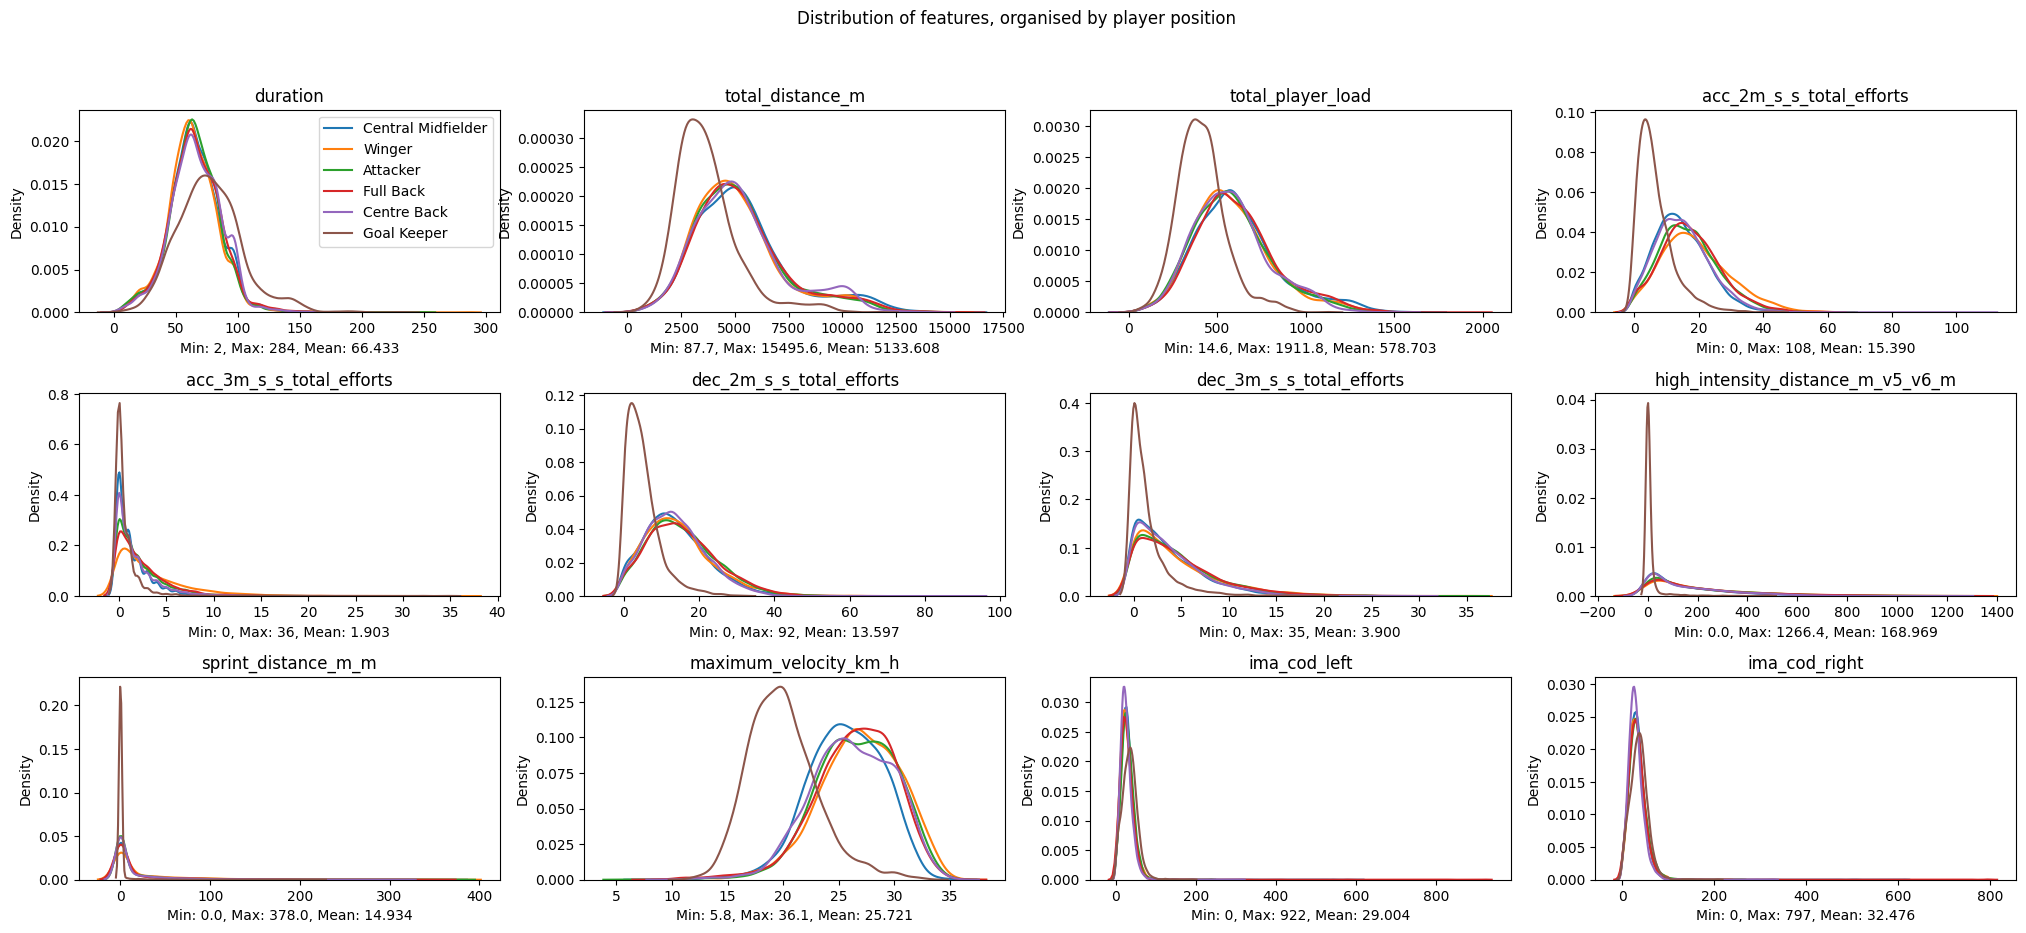

In [ ]:
# Plot distribution of features, organised by player position
fig, axs = plt.subplots(3, 4, figsize=(25, 10))
plt.subplots_adjust(hspace=0.4)

for i, column in enumerate(numeric_columns):
    ax = axs[int(i / 4), i % 4]

    for position in positions:
        position_df = df[df["position"] == position]

        if i == 0:
            sns.kdeplot(position_df[column], label=position, ax=ax)
            ax.legend()
        else:
            sns.kdeplot(position_df[column], ax=ax)

    column_min = df[column].min()
    column_max = df[column].max()
    column_mean = df[column].mean()

    ax.set_title(column)
    ax.set_xlabel(f"Min: {column_min}, Max: {column_max}, Mean: {column_mean:.3f}")

fig.suptitle("Distribution of features, organised by player position")
plt.show()

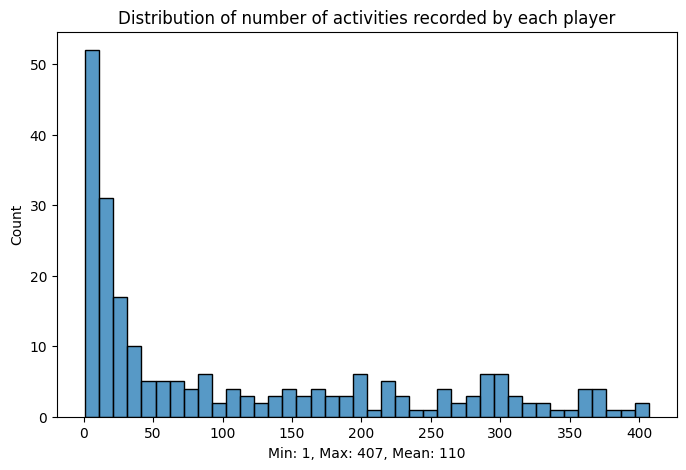

In [ ]:
# Distribution of number of activities per player
player_activity_counts = df["player"].value_counts()

fig, ax = plt.subplots(figsize=(8, 5))

sns.histplot(player_activity_counts, bins=40, ax=ax)

activity_count_min = player_activity_counts.min()
activity_count_max = player_activity_counts.max()
activity_count_mean = player_activity_counts.mean()

ax.set_title("Distribution of number of activities recorded by each player")
ax.set_xlabel(
    f"Min: {activity_count_min}, Max: {activity_count_max}, Mean: {activity_count_mean:.0f}"
)

plt.show()

### Data cleaning

The above distributions highlight the need to clean the dataset by removing activities which could be considered outliers.

First, the distribution of activity duration (`duration`) has a long tail. Whilst the average activity duration is around 1 hour, there are some activities that have a recorded duration of over 3 hours. These long activities have the potential to skew measures of athlete effort. Additionally, there are some activities with very short recorded durations. It is unlikely that metrics generated from such short activities will make meaningful contributions when measuring athlete efforts. As such, activities with a duration of less than 20 minutes, or a duration greater than 120 minutes, are removed from the analysis.

Secondly, there is some variation in the number of activities recorded by an athlete. Whilst most athletes have recorded more than 20 activities, there is a significant number of athletes who have not. To ensure more accurate representations of long term trends in athlete efforts, any athlete who has not recorded more than 20 activities is also removed from the analysis.

In [ ]:
# Check for null values
df_contains_nulls = df.isnull().values.any()

print(f"Data contains null values: {df_contains_nulls}")

Data contains null values: False


In [ ]:
# Remove instances where activity duration is too short or too long
min_duration_mins = 20
max_duration_mins = 120

df_correct_durations = df[df["duration"].between(min_duration_mins, max_duration_mins)]

print(
    f"Removed {df.shape[0] - df_correct_durations.shape[0]} rows of data as duration was too short or too long"
)
print(f"{df_correct_durations.shape[0]} rows of data remaining")

df = df_correct_durations

Removed 702 rows of data as duration was too short or too long
24124 rows of data remaining


In [ ]:
# Remove players who have not participate in a minimum number of activities
min_number_of_activities = 20

players_to_keep = []
for player in df["player"].unique():
    activity_count = df[df["player"] == player].shape[0]

    if activity_count > min_number_of_activities:
        players_to_keep.append(player)

df_correct_activity_count = df[df["player"].isin(players_to_keep)]

print(
    f"Removed {df.shape[0] - df_correct_activity_count.shape[0]} rows of data ({len(df['player'].unique()) - len(df_correct_activity_count['player'].unique())} players) of data as minimum activity count was not met"
)
print(f"{df_correct_activity_count.shape[0]} rows of data remaining")

df = df_correct_activity_count

Removed 722 rows of data (82 players) of data as minimum activity count was not met
23402 rows of data remaining


### Correlation analysis

Similar to distribution plots, plotting the correlation between features in the data can help to expose underlying trends or patterns. They can also be used to confirm existing assumptions about the data.

As expected, most features are positively correlated with the others. Most significantly, `total_player_load` is highly correlated with `total_distance_m`. This is likely because player load is a measure of accumulated accelerations and athletes whose sport involves a signficant amount of running, as is the case here, will generate a large number of vertical acceleration readings when travelling.

When splitting the correlations by player position it is worth noting that the correlation between `total_player_load` and `total_distance_m` is slightly lower for Goal Keepers than other position groups. This suggests that Goal Keepers may accumulate training load through mechanisms other than running during their activities.

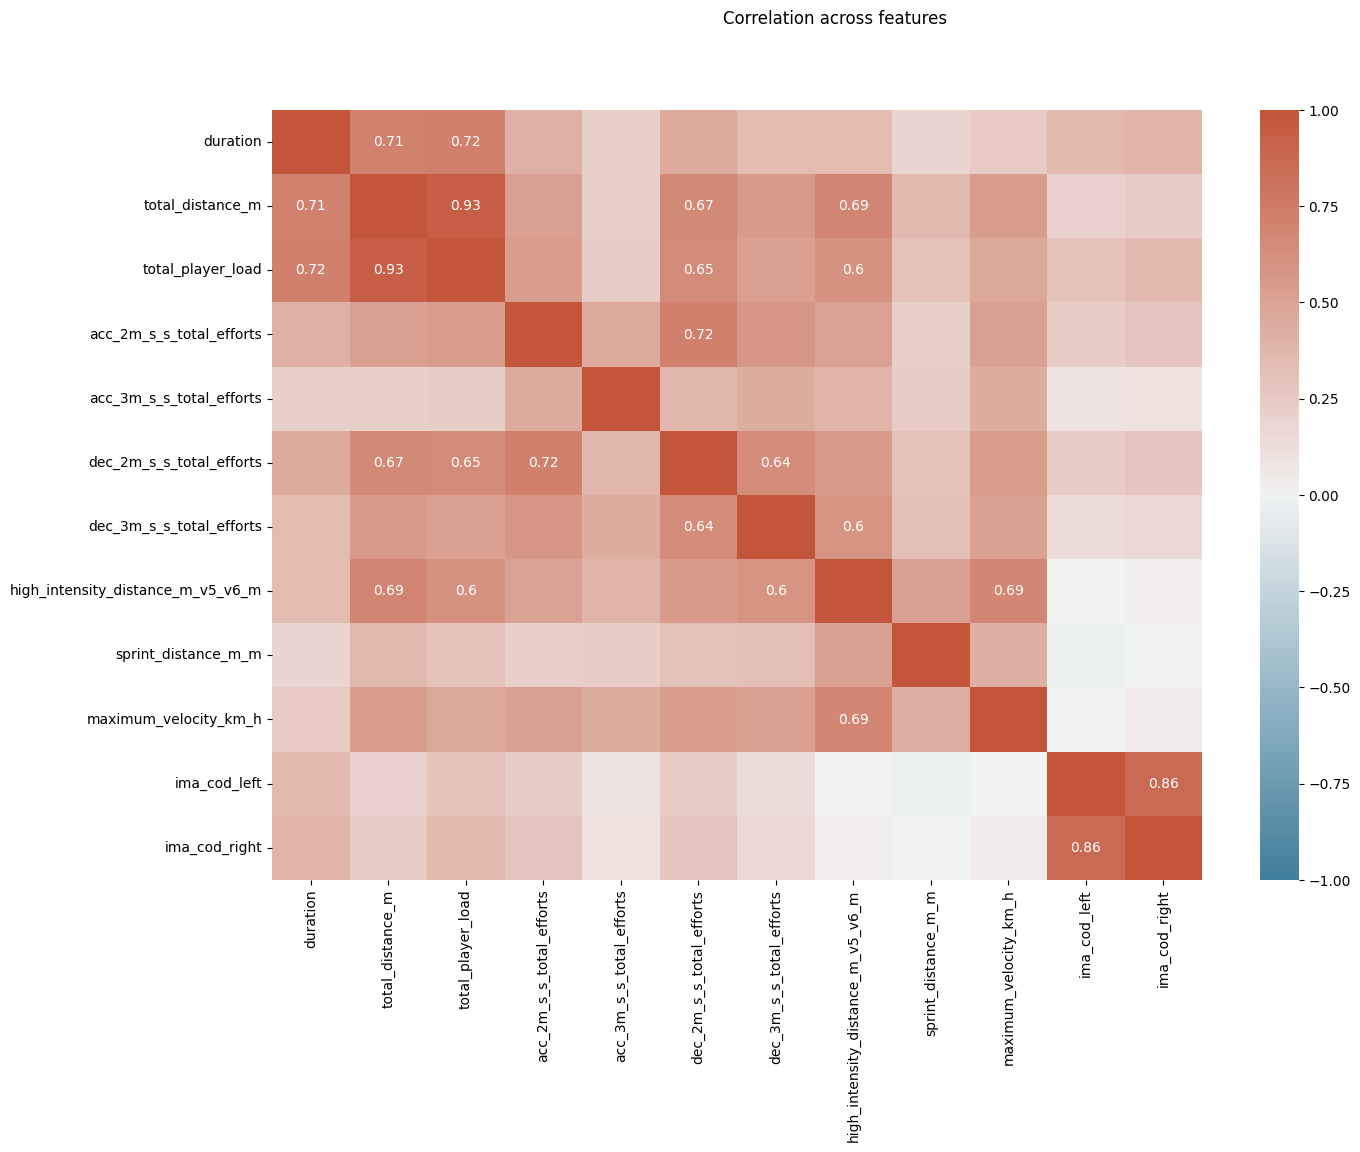

In [ ]:
# Plot correlation across features
cmap = sns.diverging_palette(230, 20, as_cmap=True)

fig, ax = plt.subplots(figsize=(15, 10))

sns.heatmap(df[numeric_columns].corr(), cmap=cmap, vmin=-1, vmax=1, annot=True, ax=ax)

for t in ax.texts:
    if 0.6 <= float(t.get_text()) < 1:
        t.set_text(t.get_text())
    else:
        t.set_text("")

fig.suptitle("Correlation across features")
plt.show()

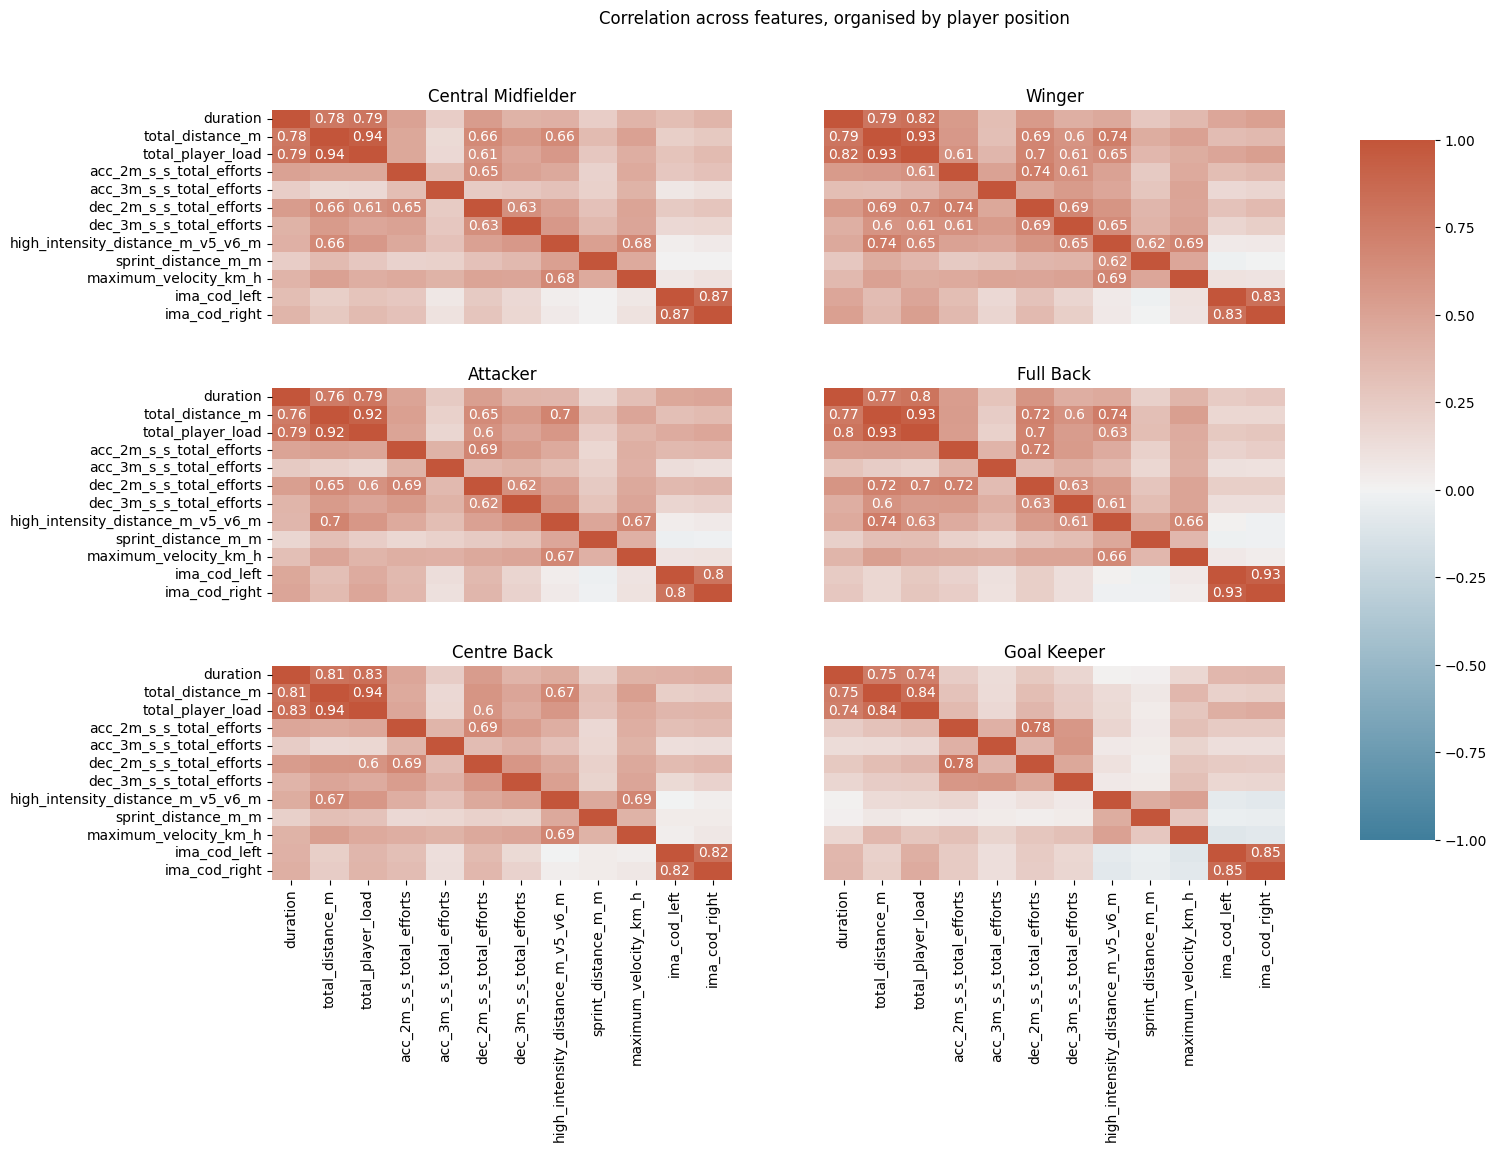

In [ ]:
# Plot correlation of features, organised by player position
fig, axs = plt.subplots(3, 2, figsize=(15, 10))
fig.subplots_adjust(right=0.8, hspace=0.3)
cbar_ax = fig.add_axes([0.85, 0.15, 0.05, 0.7])

for i, position in enumerate(positions):
    ax = axs[int(i / 2), i % 2]

    position_df = df[df["position"] == position]

    if i < 4:
        sns.heatmap(
            position_df[numeric_columns].corr(),
            cmap=cmap,
            vmin=-1,
            vmax=1,
            annot=True,
            cbar=False,
            ax=ax,
        )
    else:
        sns.heatmap(
            position_df[numeric_columns].corr(),
            cmap=cmap,
            vmin=-1,
            vmax=1,
            annot=True,
            cbar=True,
            cbar_ax=cbar_ax,
            ax=ax,
        )

    if i % 2 == 1:
        ax.set_yticks([])

    if int(i / 2) != 2:
        ax.set_xticks([])

    for t in ax.texts:
        if 0.6 <= float(t.get_text()) < 1:
            t.set_text(t.get_text())
        else:
            t.set_text("")

    ax.set_title(position)

fig.suptitle("Correlation across features, organised by player position")
plt.show()

## Anaylsis

### Assessing athlete effort

Assessing athlete effort can be done through a number of metrics. Simple measures such as distance covered, number of sprints, duration etc. can be used as basic indicators of the effort an athlete has exerted during an activity. Whilst these are easy to understand they are considered basic, and often do not give a full representation of the effort an athlete has exerted during an activity. Additionally, these measures are not independent of the length of an activity, making comparisons across activities challenging.

An alternative measure would be the `total_player_load` metric provided in the data. This is an estimate of athlete effort that combines accelerations in multiple directions and gives a single number that can be used as an objective measure of athlete effort. There are however are some drawbacks. For example, longer training sessions may lead to a higher accumulated load even if the athlete is operating within a consistent intensity level. Although longer activities likely do require higher effort from an athlete, the intensity of a training session is more likely to represent the effort an athlete has exerted. Intuitively, shorter but more intense sessions require more effort from an athlete than longer low-intensity activites.

It is therefore more interesting to view changes of the `total_player_load` metric in the context of other measures. In this line, a new metric, `training_intensity`, is introduced. This is calculated by measuring `total_player_load` per `duration` for an activity, aiming to give an indication of the intensity the athlete was working at rather than a simple measure of their overall load during an activity.

Additionally, it is may be interesting to consider athlete efforts over varying time frames, rather than at a per-activity level. Research suggests that two aggregations of athlete effort across activities are important to consider:

- `acute_training_intensity`: Refers to the amount of effort an athlete undertakes within a given week of training (i.e. a 7 day window)
- `chronic_training_intensity`: Refers to the average acute load an athlete undertakes over a four week period (i.e a 28 day window)

In [ ]:
# Calculate training intensity for all activities
df["training_intensity"] = df["total_player_load"] / df["duration"]

# Calculate acute training intensity
df["acute_training_intensity"] = np.nan
for player in df["player"].unique():
    player_df = df[df["player"] == player]
    indexes = player_df.index

    player_df = player_df.set_index("date", drop=False)

    acute_training_intensity = (
        player_df["training_intensity"].rolling(window="7d", min_periods=2).sum()
    )
    df.loc[indexes, "acute_training_intensity"] = acute_training_intensity.values

# Calculate chronic training intensity
df["chronic_training_intensity"] = np.nan
for player in df["player"].unique():
    player_df = df[df["player"] == player]
    indexes = player_df.index

    player_df = player_df.set_index("date", drop=False)

    chronic_training_intensity = (
        player_df["acute_training_intensity"]
        .rolling(window="28d", min_periods=5)
        .mean()
    )
    df.loc[indexes, "chronic_training_intensity"] = chronic_training_intensity.values

### Determining "overreaching" efforts

Observing trends over time in an athlete's `training_intensity` can already provide useful information to coaching staff. However, understanding the implications of these trends can be difficult, especially when trying to gather insights across multiple players. To help with this analysis, the concept of "overreaching" is introduced. Activities where an athlete is identified to be "overreaching" can be defined as an activity where an athlete's training intensity exceeds the expected or normal range. The ability to automatically identify these activities reduces the workload of coaching staff and can alert them to instances where an athletes health may need to be more closely monitored.

Two indicators of "overreaching" are introduced in this report.

The first indicator, `overreaching_acute_training_intensity`, is based solely on changes in an athlete's `acute_training_intensity`. Studies suggest that athletes should aim to increase weekly workloads by no more than 10% to maintain safe progress. Increases in `acute_training_intensity` above this threshold are flagged as being "overreaching" activities.

The second indicator, `overreaching_acute_chronic_workload_ratio`, focuses on the relation between fatigue and fitness. Fatigue is often characterised by short term measures of workload (i.e. `acute_training_intensity`), whereas fitness can be characterised by longer term measures of workload (i.e. `chronic_training_intensity`). Research suggests that the optimal ratio of acute to chronic training intensity lies between 0.8 and 1.3. Based on this, "overreaching" activities can be identified as those where this ratio exceeds a value of 1.3.

In [ ]:
# Calculate overreaching based on rate of increase in acute training intensity
safe_acute_training_intensity_increase = 1.1

df["overreaching_acute_training_intensity_increase"] = False
for player in df["player"].unique():
    player_df = df[df["player"] == player]
    indexes = player_df.index

    overreaching_acute_training_intensity = np.where(
        player_df["acute_training_intensity"]
        > (
            player_df["acute_training_intensity"].shift()
            * safe_acute_training_intensity_increase
        ),
        True,
        False,
    )
    df.loc[indexes, "overreaching_acute_training_intensity_increase"] = (
        overreaching_acute_training_intensity
    )


# Calculate overreaching based on acute:chronic workload ratio
safe_acute_chronic_workload_ratio_bounds = (0.8, 1.3)
df["overreaching_acute_chronic_workload_ratio"] = np.where(
    (df["acute_training_intensity"] / df["chronic_training_intensity"])
    > safe_acute_chronic_workload_ratio_bounds[1],
    True,
    False,
)

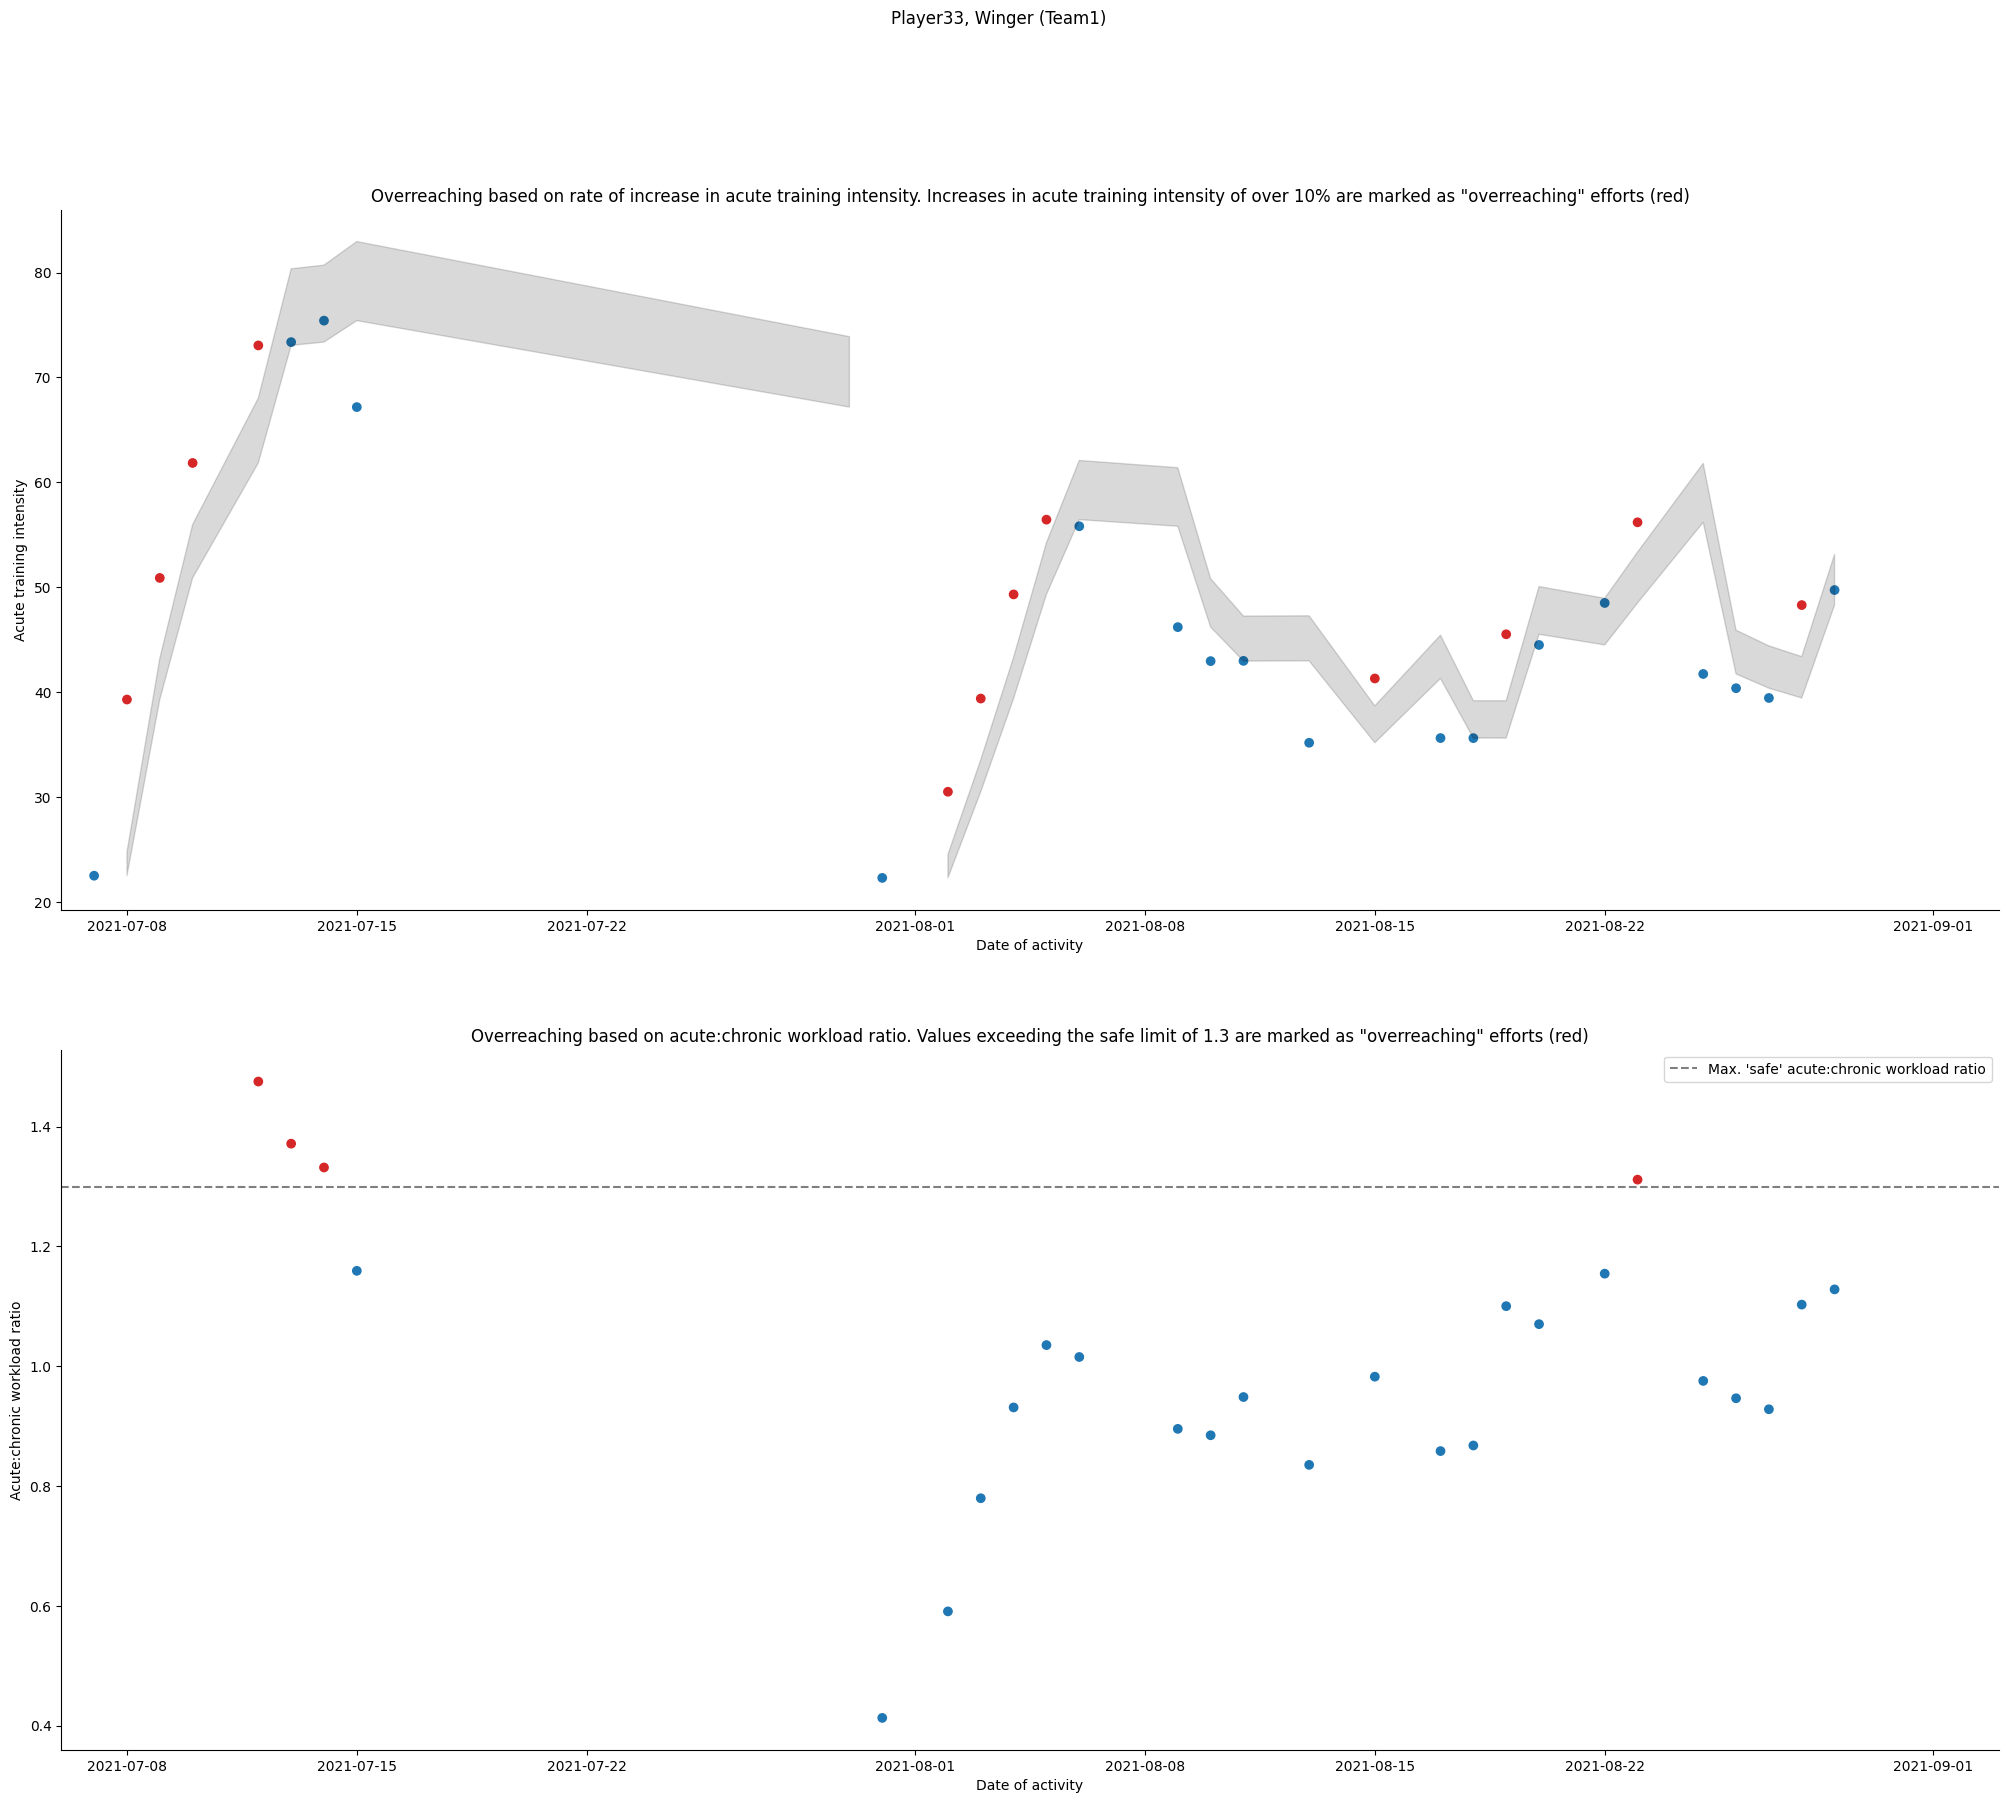

In [ ]:
player = list(df["player"].unique())[21]

player_df = df[df["player"] == player]

start_date = player_df["date"].min()
end_date = player_df["date"].max()


# Plot overreaching metrics for an athlete
fig, axs = plt.subplots(2, 1, figsize=(25, 20))
fig.suptitle(
    f"{player}, {player_df['position'].unique()[0]} ({(', ').join(player_df['team_name'].unique())})"
)

# Overreaching based on rate of increase in acute training intensity
ax = axs[0]
ax.spines[["right", "top"]].set_visible(False)

ax.set_title(
    'Overreaching based on rate of increase in acute training intensity. Increases in acute training intensity of over 10% are marked as "overreaching" efforts (red)'
)
ax.set_xlabel("Date of activity")
ax.set_ylabel("Acute training intensity")

ax.set_xlim(start_date, end_date + datetime.timedelta(days=5))

ax.scatter(
    player_df["date"],
    player_df["acute_training_intensity"],
    c=np.where(player_df["overreaching_acute_training_intensity_increase"], "C3", "C0"),
)

ax.fill_between(
    player_df["date"],
    player_df["acute_training_intensity"].shift(),
    player_df["acute_training_intensity"].shift()
    * safe_acute_training_intensity_increase,
    color="black",
    alpha=0.15,
)

ax = axs[1]
ax.spines[["right", "top"]].set_visible(False)

ax.set_title(
    f'Overreaching based on acute:chronic workload ratio. Values exceeding the safe limit of {safe_acute_chronic_workload_ratio_bounds[1]} are marked as "overreaching" efforts (red)'
)
ax.set_xlabel("Date of activity")
ax.set_ylabel("Acute:chronic workload ratio")

ax.set_xlim(start_date, end_date + datetime.timedelta(days=5))

ax.axhline(
    safe_acute_chronic_workload_ratio_bounds[1],
    color="black",
    ls="--",
    alpha=0.5,
    label="Max. 'safe' acute:chronic workload ratio",
)

ax.scatter(
    player_df["date"],
    (player_df["acute_training_intensity"] / player_df["chronic_training_intensity"]),
    c=np.where(player_df["overreaching_acute_chronic_workload_ratio"], "C3", "C0"),
)

ax.legend()

plt.show()

The above plots show the activity history for a given player, highlighting activities identified as "overreaching" based on the two calculated metrics. Plots such as this one can be used by coaching staff to identify trends in an athlete's training intensity. Specifically, observing the spread and occurence rates of "overreaching" activities could be used to adjust training programs, either by prioritising recovery time or reducing the intensity of future sessions.

### Identifying injuries

As injury information is not included in the data some heuristic is needed to determine whether an athlete has suffered from injury or not. Assuming a healthy athlete would participate in all training sessions, and assuming that a "normal" training schedule has multiple sessions during a week, a proxy based on time without recorded activity can be used in place of true injury data.

Additionally, it is not possible to derive the cause of injury from the data provided. Again here, an assumption is made that any identified injuries were sustained during the activity that preceeded an athlete taking time out, rather than the injury occuring outside of recorded training activites.

In [ ]:
# Calculate time between activities for individual athletes
df["previous_activity_date"] = df.groupby(["player"])["date"].shift()
df["days_since_last_activity"] = (
    df["date"] - df["previous_activity_date"]
) / np.timedelta64(1, "D")
df["days_since_last_activity"] = df["days_since_last_activity"].fillna(0)

# Calculate activities where an athlete is assumed to be returning from injury
# based on time between activites
days_since_last_activity_injury_threshold = 14
df["returning_from_injury"] = np.where(
    df["days_since_last_activity"] > days_since_last_activity_injury_threshold,
    True,
    False,
)

# Assume an athlete sustained an injury on the activity recorded prior to them returning
# from injury
df["sustained_injury"] = df.groupby(["player"])["returning_from_injury"].shift(-1)

### Correlating "overreaching" efforts with injuries

The final analysis aims to answer whether the two indicators of "overreaching" activities can be used to identify whether an athlete is at an increased risk of injury.

This is first done by correlating the number of "overreaching" activities an athlete is exposed to with the number of injuries they have sustained. Fitting an independent Ordinary Least Squares (OLS) regression model for each "overreaching" metric shows a significant positive correlation between both "overreaching" metrics and the number of sustained injuries. This suggests that the number of "overreaching" activities that an athlete exposes themselves to may be a good predictor of injury likelihood.

Plotting the number of "overreaching" activities against the number of sustained injuries across all athletes shows this correlation more clearly. Most importantly, athletes who have sustained no injuries are shown to have had significantly fewer "overreaching" efforts compared to athletes who have sustained at least one injury.

In [ ]:
# Calculate correlations between overreaching efforts and number of injuries
number_overreaching_acute_training_intensity_increase = []
number_overreaching_acute_chronic_workload_ratio = []
number_injuries = []

for player in df["player"].unique():
    player_df = df[df["player"] == player]

    number_overreaching_acute_training_intensity_increase.append(
        player_df["overreaching_acute_training_intensity_increase"].sum()
    )
    number_overreaching_acute_chronic_workload_ratio.append(
        player_df["overreaching_acute_chronic_workload_ratio"].sum()
    )
    number_injuries.append(player_df["sustained_injury"].sum())

acute_training_intensity_increase_model = sm.OLS(
    number_injuries,
    sm.add_constant(number_overreaching_acute_training_intensity_increase),
).fit()
print(
    'Correlation between number of "overreaching" efforts, based on rate of increase in acute training intensity, and number of sustained injuries:'
)
print(acute_training_intensity_increase_model.summary())

print()

acute_chronic_workload_ratio_model = sm.OLS(
    number_injuries,
    sm.add_constant(number_overreaching_acute_chronic_workload_ratio),
).fit()
print(
    'Correlation between number of "overreaching" efforts, based on acute:chronic workload ratio, and number of sustained injuries:'
)
print(acute_chronic_workload_ratio_model.summary())

Correlation between number of "overreaching" efforts, based on rate of increase in acute training intensity, and number of sustained injuries:
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.075
Model:                            OLS   Adj. R-squared:                  0.068
Method:                 Least Squares   F-statistic:                     11.39
Date:                Fri, 07 Jun 2024   Prob (F-statistic):           0.000954
Time:                        13:58:10   Log-Likelihood:                -306.56
No. Observations:                 143   AIC:                             617.1
Df Residuals:                     141   BIC:                             623.0
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025 

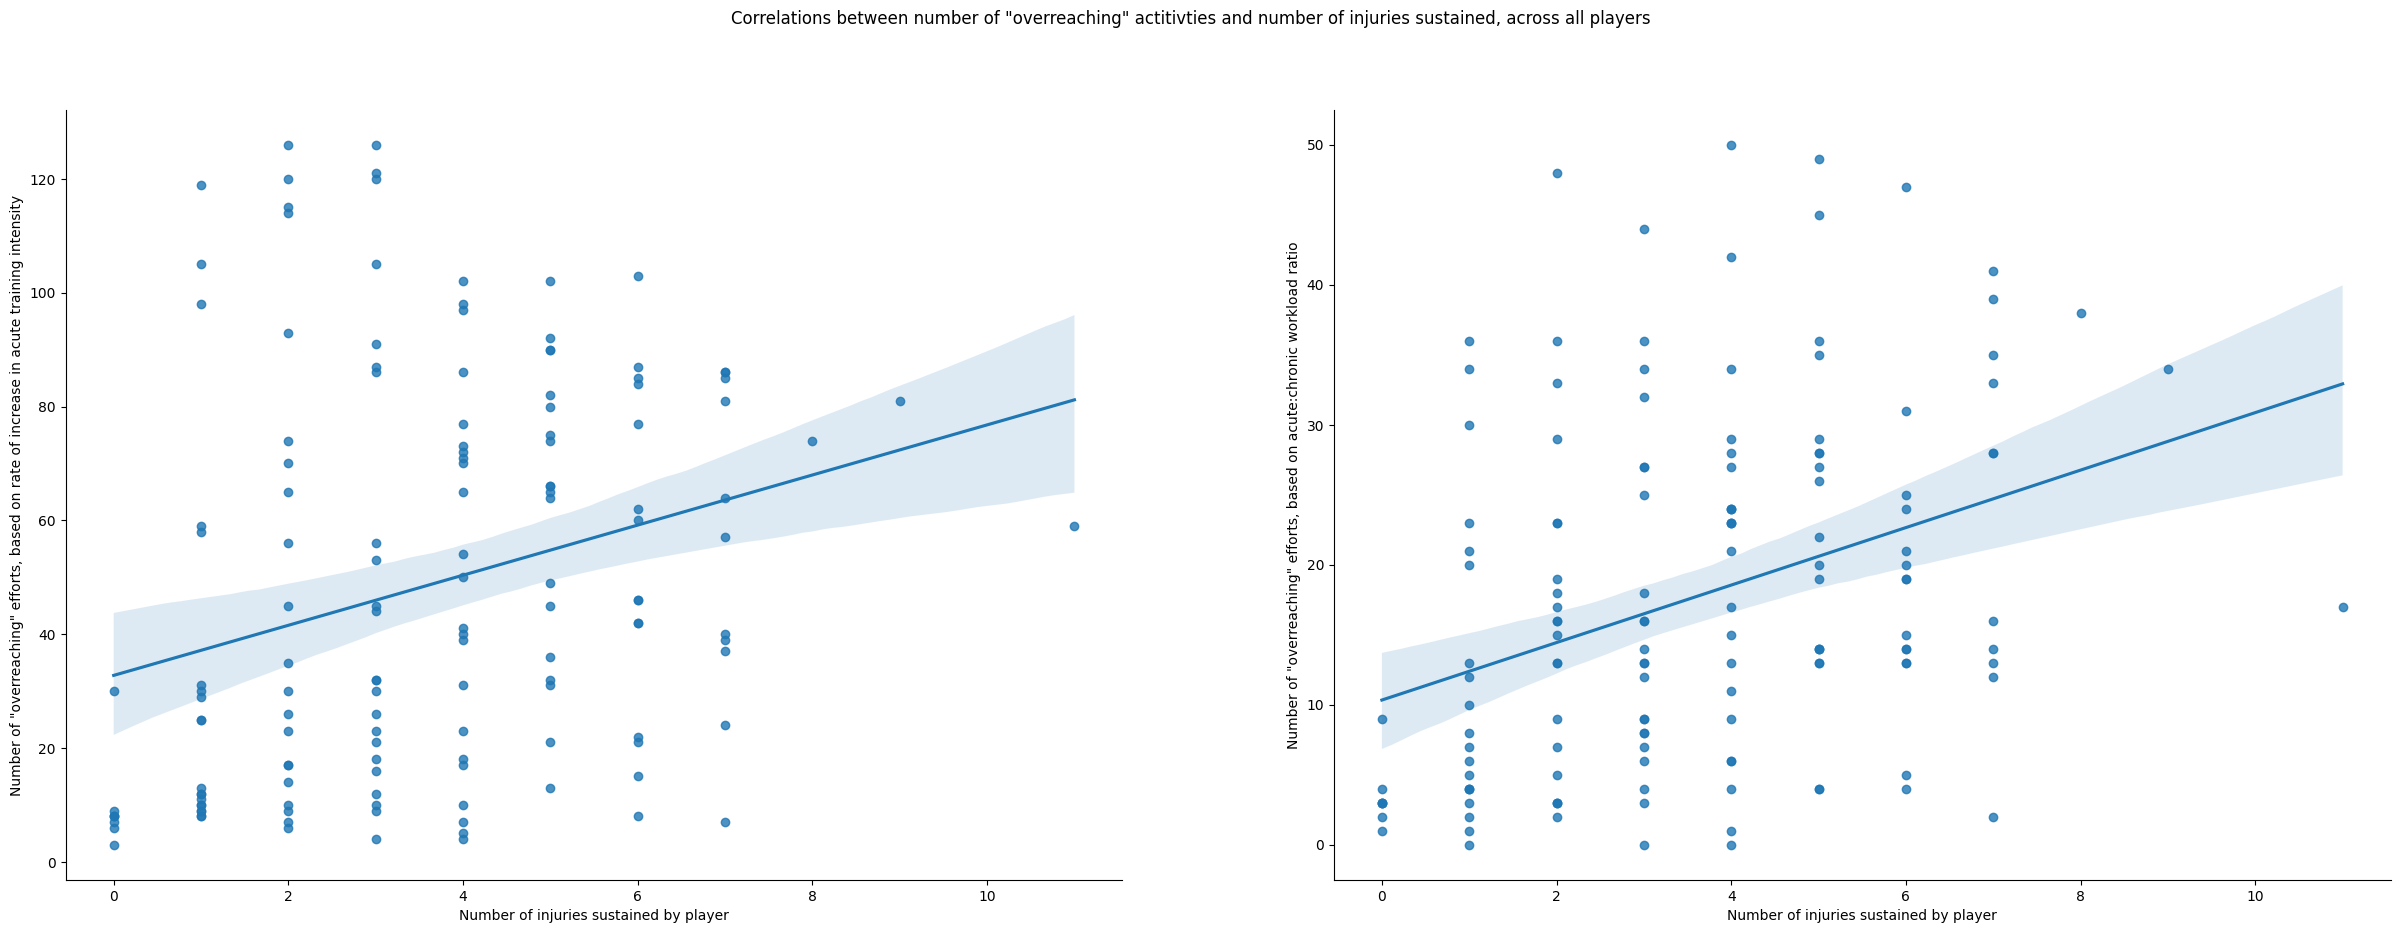

In [ ]:
# Plot number of overeaching efforts against number of injuries for all players
fig, axs = plt.subplots(1, 2, figsize=(30, 10))
fig.suptitle(
    'Correlations between number of "overreaching" actitivties and number of injuries sustained, across all players'
)

ax = axs[0]
ax.spines[["right", "top"]].set_visible(False)

ax.set_xlabel("Number of injuries sustained by player")
ax.set_ylabel(
    'Number of "overreaching" efforts, based on rate of increase in acute training intensity'
)

sns.regplot(
    x=number_injuries, y=number_overreaching_acute_training_intensity_increase, ax=ax
)

ax = axs[1]
ax.spines[["right", "top"]].set_visible(False)

ax.set_xlabel("Number of injuries sustained by player")
ax.set_ylabel('Number of "overreaching" efforts, based on acute:chronic workload ratio')

sns.regplot(
    x=number_injuries, y=number_overreaching_acute_chronic_workload_ratio, ax=ax
)

plt.show()

## Conclusions

This report introduces two metrics for identifying whether an athlete has "overreached" during a training session. Both these metrics are shown to correlate well with the number of injuries that an athlete has suffered.

Coaching staff may aim to include analysis of these metrics as part of athlete health reports. Identifying athletes who have consistently been "overreaching" can be useful in creating tailored training plans and ensuring the overall health of a squad. Limiting the number of "overreaching" activities that an athlete is exposed can reduce risk of injury whilst still allowing for gains in athletic performance.

### Live implementation

Whilst this analysis has been conducted on historic data, the two metrics introduced can also be implemented in a live scenario.

Calculations of `overreaching_acute_training_intensity` and `overreaching_acute_chronic_workload_ratio` can be made as soon as data has been collected from an athlete after a training session. Using these to provide instant feedback on whether an athlete has "overreached" may allow for quicker responses from coaching staff, especially when recovery needs can be immediately prioritised.

### Further analysis

Further developments on the concepts of "overreaching" may help to provide further insights on athlete health.

Most notably, the dataset used for this analysis does not include accurate injury data for athletes. Including concrete injury data as part of a future analysis is likely to expose clearer relationships between "overreaching" activities and risk of injury for an athlete. Additionally, categorisations of injuries may allow for more fine grained insights into what types of injuries athletes who "overreach" are at an increased risk of. It is likely that muscle-strain injuries are more closely linked with the two measures introduced in this report when compared with contact injuries.

Future analysis should also aim to investigate different time frames for `acute_training_intensity` and `chronic_training_intensity` workloads. Whilst the measures of 7 days and 28 days respectively are good generalisations, there is a potential that the seasonality of football impacts fatigue and fitness measures within athletes in different ways.

Finally, it may be interesting to investigate whether there are any trends in the frequency of "overreaching" efforts just before an injury is sustained. Whilst this investigation has shown that an increase in the overall number of "overreaching" efforts increases the likelihood of an injury, it would be interesting to understand whether more concentrated "overreaching" efforts over a short term period (e.g. 2 weeks) is more likely to lead to an athlete suffering from an injury. From this it may be possible for coaching staff to allocate "overreaching" efforts to athletes at optimal times within a training schedule, helping to further maximise performance gains whilst still maintaining a low risk of injury.

## References

- https://www.scienceforsport.com/how-load-management-can-help-reduce-injury-risk-in-youth-athletes/
- https://www.physio-pedia.com/Load_Management
- https://support.catapultsports.com/hc/en-us/articles/360000510795-What-is-Player-Load
- https://www.catapult.com/blog/fundamentals-playerload-athlete-work
- https://www.13thbeachhealthservices.com.au/blog/a-beginners-guide-to-what-acute-chronic-workload-is-and-why-it-is-important/
- https://www.scienceforsport.com/acutechronic-workload-ratio/